In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    'Month': [
        'Jan', 'Feb', 'Mar', 'Apr', 'May',
        'Jan', 'Feb', 'Mar', 'Apr', 'May'
    ],

    'Crop': [
        'Wheat', 'Wheat', 'Wheat', 'Wheat', 'Wheat',
        'Soybean', 'Soybean', 'Soybean', 'Soybean', 'Soybean'
    ],

    'Production': [
        1200, 1350, 1500, 1600, 1550,
        900, 950, 1100, 1050, 1200
    ],

    'Price': [
        2600, 2650, 2700, 2750, 2800,
        4200, 4150, 4300, 4400, 4350
    ],

    'Arrivals': [
        120, 130, 145, 150, 140,
        85, 90, 100, 95, 110
    ]
}

df = pd.DataFrame(data)

print(df)

  Month     Crop  Production  Price  Arrivals
0   Jan    Wheat        1200   2600       120
1   Feb    Wheat        1350   2650       130
2   Mar    Wheat        1500   2700       145
3   Apr    Wheat        1600   2750       150
4   May    Wheat        1550   2800       140
5   Jan  Soybean         900   4200        85
6   Feb  Soybean         950   4150        90
7   Mar  Soybean        1100   4300       100
8   Apr  Soybean        1050   4400        95
9   May  Soybean        1200   4350       110


In [3]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Month       10 non-null     object
 1   Crop        10 non-null     object
 2   Production  10 non-null     int64 
 3   Price       10 non-null     int64 
 4   Arrivals    10 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 532.0+ bytes

Statistical Summary:
        Production        Price    Arrivals
count    10.000000    10.000000   10.000000
mean   1240.000000  3490.000000  116.500000
std     250.333111   837.257428   23.926972
min     900.000000  2600.000000   85.000000
25%    1062.500000  2712.500000   96.250000
50%    1200.000000  3475.000000  115.000000
75%    1462.500000  4275.000000  137.500000
max    1600.000000  4400.000000  150.000000

Missing Values:
Month         0
Crop          0
Production    0
Price         0
Arrivals      0
dtype: int64


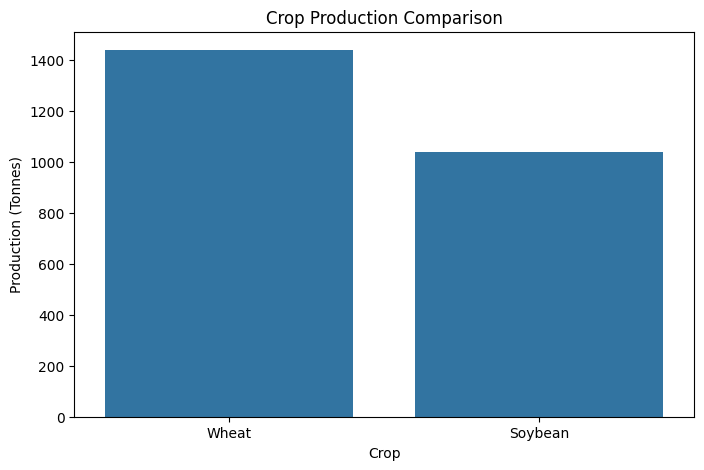

In [4]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Crop',
    y='Production',
    errorbar=None
)

plt.title('Crop Production Comparison')
plt.xlabel('Crop')
plt.ylabel('Production (Tonnes)')

plt.show()

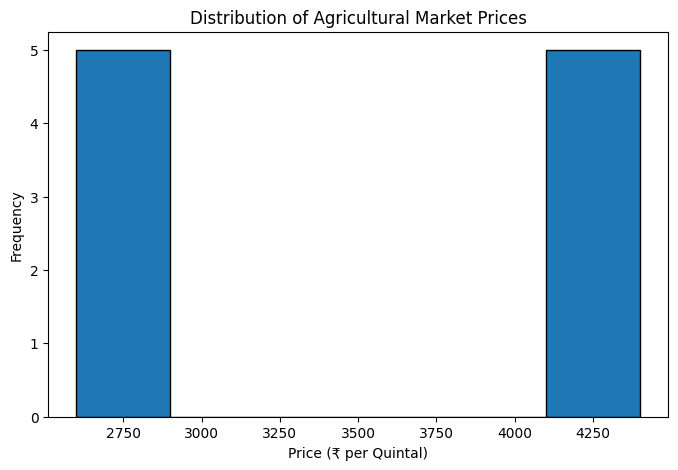

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(df['Price'], bins=6, edgecolor='black')

plt.title('Distribution of Agricultural Market Prices')
plt.xlabel('Price (₹ per Quintal)')
plt.ylabel('Frequency')

plt.show()

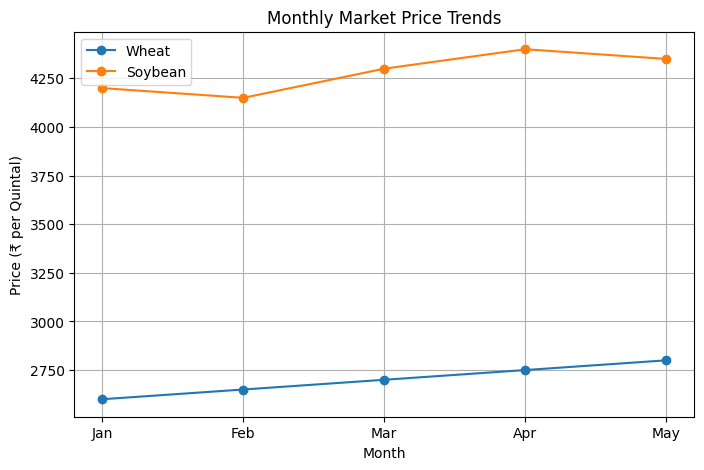

In [6]:
plt.figure(figsize=(8, 5))

for crop in df['Crop'].unique():
    crop_data = df[df['Crop'] == crop]

    plt.plot(
        crop_data['Month'],
        crop_data['Price'],
        marker='o',
        label=crop
    )

plt.title('Monthly Market Price Trends')
plt.xlabel('Month')
plt.ylabel('Price (₹ per Quintal)')
plt.legend()
plt.grid(True)

plt.show()

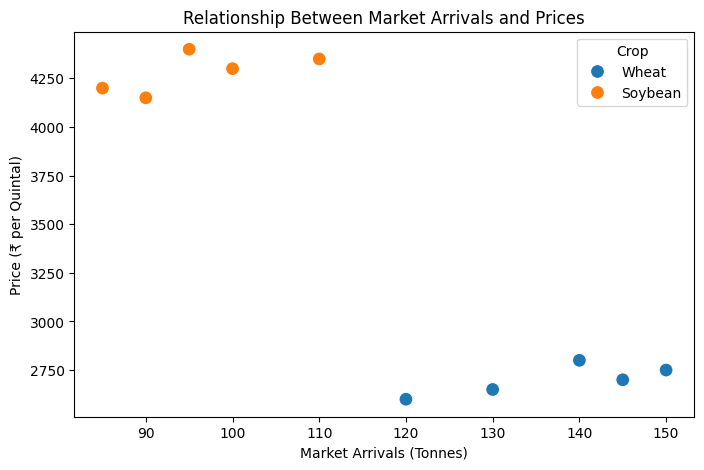

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Arrivals',
    y='Price',
    hue='Crop',
    s=100
)

plt.title('Relationship Between Market Arrivals and Prices')
plt.xlabel('Market Arrivals (Tonnes)')
plt.ylabel('Price (₹ per Quintal)')

plt.show()

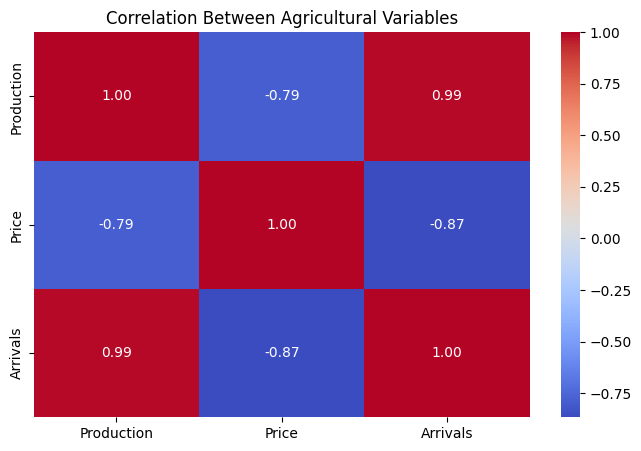

In [8]:
plt.figure(figsize=(8, 5))

correlation = df[['Production', 'Price', 'Arrivals']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Agricultural Variables')

plt.show()

In [9]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Price'] < lower_limit) |
    (df['Price'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

print("\nPotential Price Outliers:")
print(outliers[['Crop', 'Month', 'Price']])

Lower Limit: 368.75
Upper Limit: 6618.75

Potential Price Outliers:
Empty DataFrame
Columns: [Crop, Month, Price]
Index: []


In [10]:
correlation = df[['Production', 'Price', 'Arrivals']].corr()

print("Correlation Matrix:")
print(correlation.round(2))

Correlation Matrix:
            Production  Price  Arrivals
Production        1.00  -0.79      0.99
Price            -0.79   1.00     -0.87
Arrivals          0.99  -0.87      1.00


In [11]:
df.to_csv('week3_agriculture_sample.csv', index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


## Supplementary analysis: regional production

The following additional dataset is fictional and is used only to demonstrate state-wise comparison. It is separate from the original 10-row dataset.

In [ ]:
regional_data = {
    'State': ['Maharashtra', 'Madhya Pradesh', 'Rajasthan', 'Uttar Pradesh',
              'Maharashtra', 'Madhya Pradesh', 'Rajasthan', 'Uttar Pradesh'],
    'Crop': ['Wheat', 'Wheat', 'Wheat', 'Wheat',
             'Soybean', 'Soybean', 'Soybean', 'Soybean'],
    'Production_Tonnes': [1800, 2200, 1500, 2500, 1600, 1900, 1300, 1100]
}

regional_df = pd.DataFrame(regional_data)
print(regional_df)


In [ ]:
regional_pivot = regional_df.pivot(
    index='State', columns='Crop', values='Production_Tonnes'
)

regional_pivot.plot(kind='bar', figsize=(8, 5))
plt.title('Sample Crop Production by State')
plt.xlabel('State')
plt.ylabel('Production (Tonnes)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()


## Supplementary analysis: seasonal price trends

This fictional 12-month dataset demonstrates how a full-year trend analysis could be structured. It is not official market-price data.

In [ ]:
seasonal_data = {
    'Month': ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
              'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'],
    'Wheat_Price': [2600, 2620, 2650, 2700, 2740, 2760,
                    2730, 2710, 2690, 2720, 2750, 2780],
    'Soybean_Price': [4200, 4180, 4250, 4320, 4380, 4350,
                      4290, 4260, 4310, 4370, 4400, 4360]
}

seasonal_df = pd.DataFrame(seasonal_data)
print(seasonal_df)


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(seasonal_df['Month'], seasonal_df['Wheat_Price'],
         marker='o', label='Wheat')
plt.plot(seasonal_df['Month'], seasonal_df['Soybean_Price'],
         marker='o', label='Soybean')

plt.title('Illustrative Full-Year Monthly Price Pattern')
plt.xlabel('Month')
plt.ylabel('Price (₹ per Quintal)')
plt.legend()
plt.grid(True)
plt.show()


## Interpretation and limitation

The regional chart compares fictional production values across four states. The 12-month line chart demonstrates a full-year seasonal analysis format. These additional datasets are illustrative only and must not be represented as actual state production or official market prices.